# DLPFC Data

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import os
import random
from sklearn.metrics import adjusted_rand_score

import scSLAT
from scSLAT.model import Cal_Spatial_Net, load_anndatas, run_SLAT, spatial_match
from scSLAT.viz import match_3D_multi, hist, Sankey

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [4]:
# for loading DLPFC12 data
def load_DLPFC(root_dir='./DLPFC12', section_id='151507'):
    # 151507, ..., 151676
    # 12 in total, 7 layers
    # 151507: n_obs × n_vars = 4221 × 33538
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file=section_id+'_filtered_feature_bc_matrix.h5')
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    print("spot num", ad)
    return ad

In [10]:
ad = load_DLPFC(root_dir='/hpc/group/hickeylab/fl135/pkl_data', section_id='151507')
ad_target = load_DLPFC(root_dir='/hpc/group/hickeylab/fl135/pkl_data', section_id='151508')

spot num AnnData object with n_obs × n_vars = 4221 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spot num AnnData object with n_obs × n_vars = 4381 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


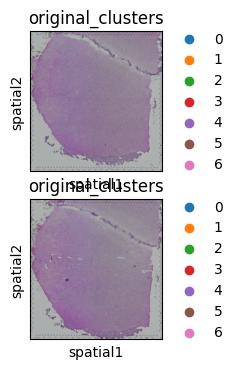

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='original_clusters', spot_size=5, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=5, ax=axes[1], show=False)
plt.show()

In [12]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)  # If using multi-GPU
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False  # May slow down training


def cal_laa_ari(ad_df):
    true_clusters_mapped_region = []  # Define lists inside the function
    mapped_clusters_mapped_region = []
    cnt = 0  
    
    for i in range(len(ad_df)):
        f1_cluster = ad_df.iloc[i]['target_celltype']
        f2_cluster = ad_df.iloc[i]['celltype']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(ad_df)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari

In [13]:
seeds_to_run = [2024, 1, 2, 3, 4, 10, 11, 12, 13, 14]

# seeds_to_run = [2024, 1]

for seed in seeds_to_run:
    print('--------------'+ str(seed))
    set_seed(seed)
    
    # Calculating spatial neighbor graph
    Cal_Spatial_Net(ad_target, k_cutoff=10, model='KNN')
    Cal_Spatial_Net(ad, k_cutoff=10, model='KNN')
    
    # Use DPCA feature to format graph
    edges, features = load_anndatas([ad_target, ad], feature='DPCA', check_order=False)
    embd0, embd1, time = run_SLAT(features, edges)
    best, index, distance = spatial_match([embd0, embd1], adatas=[ad_target, ad], reorder=False)
    
    ad_target_df = pd.DataFrame({'index': range(embd0.shape[0]),
                            'x': ad_target.obsm['spatial'][:,0],
                            'y': ad_target.obsm['spatial'][:,1],
                            'celltype': ad_target.obs['original_clusters']})
    ad_df = pd.DataFrame({'index': range(embd1.shape[0]),
                            'x': ad.obsm['spatial'][:,0],
                            'y': ad.obsm['spatial'][:,1],
                            'celltype': ad.obs['original_clusters']})

    matching = np.array([range(index.shape[0]), best])
    best_match = distance[:,0]

    ad_df['target_index'] = best
    ad_df['target_celltype'] = ad_target_df.iloc[matching[1,:],:]['celltype'].to_list()
    ad_df['cos_similarity'] = best_match
    
    ad_df.to_csv(f'/pkl_data/{seed}/DLPFC_151507.csv', index=False)
    
    laa,ari = cal_laa_ari(ad_df)
    print(f'LAA: {laa}')
    print(f'ARI: {ari}')
    
    column = '151507_151508'
    filename = '151507_151510_ARI.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    header = [' ', '151507_151508']
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        first_row = [[0, ari]]
        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_csv(excel_path, index=False)
        
    filename = '151507_151510_LAA.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        first_row = [[0, laa]]
        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_csv(excel_path, index=False)
        
    filename = '151507_151510_RunTime.xlsx'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        first_row = [[0, time]]
        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_excel(excel_path, index=False)

--------------2024
Calculating spatial neighbor graph ...
The graph contains 45803 edges, 4381 cells.
10.454918968272084 neighbors per cell on average.
Calculating spatial neighbor graph ...
The graph contains 44487 edges, 4221 cells.
10.539445628997868 neighbors per cell on average.
Use DPCA feature to format graph
Warning! Dual PCA is using GPU, which may lead to OUT OF GPU MEMORY in big dataset!
Choose GPU:0 as device
Running
Training model time: 1.10
LAA: 0.6579009713338072
ARI: 0.46955937691542565
      151507_151508
0  0       0.469559
      151507_151508
0  0       0.657901
      151507_151508
0  0       1.096866
--------------1
Calculating spatial neighbor graph ...
The graph contains 45803 edges, 4381 cells.
10.454918968272084 neighbors per cell on average.
Calculating spatial neighbor graph ...
The graph contains 44487 edges, 4221 cells.
10.539445628997868 neighbors per cell on average.
Use DPCA feature to format graph
Warning! Dual PCA is using GPU, which may lead to OUT OF 

In [ ]:
seeds_to_run = [2024, 1, 2, 3, 4, 10, 11, 12, 13, 14]

# seeds_to_run = [2024, 1]

for seed in seeds_to_run:
    print('--------------'+ str(seed))
    set_seed(seed)
    
    # Calculating spatial neighbor graph
    Cal_Spatial_Net(ad_target, k_cutoff=10, model='KNN')
    Cal_Spatial_Net(ad, k_cutoff=10, model='KNN')
    
    # Use DPCA feature to format graph
    edges, features = load_anndatas([ad_target, ad], feature='DPCA', check_order=False)
    embd0, embd1, time = run_SLAT(features, edges)
    best, index, distance = spatial_match([embd0, embd1], adatas=[ad_target, ad], reorder=False)
    
    ad_target_df = pd.DataFrame({'index': range(embd0.shape[0]),
                            'x': ad_target.obsm['spatial'][:,0],
                            'y': ad_target.obsm['spatial'][:,1],
                            'celltype': ad_target.obs['original_clusters']})
    ad_df = pd.DataFrame({'index': range(embd1.shape[0]),
                            'x': ad.obsm['spatial'][:,0],
                            'y': ad.obsm['spatial'][:,1],
                            'celltype': ad.obs['original_clusters']})

    matching = np.array([range(index.shape[0]), best])
    best_match = distance[:,0]

    ad_df['target_index'] = best
    ad_df['target_celltype'] = ad_target_df.iloc[matching[1,:],:]['celltype'].to_list()
    ad_df['cos_similarity'] = best_match
    
    ad_df.to_csv(f'/pkl_data/{seed}/DLPFC_151508.csv', index=False)
    
    laa,ari = cal_laa_ari(ad_df)
    print(f'LAA: {laa}')
    print(f'ARI: {ari}')
    
    column = '151508_151509'
    filename = '151507_151510_ARI.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Load existing file
    df = pd.read_csv(excel_path)
    df.at[0, column] = ari
    print(df)
    # Save as a CSV file
    df.to_csv(excel_path, index=False)
        
    filename = '151507_151510_LAA.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Load existing file
    df = pd.read_csv(excel_path)
    df.at[0, column] = laa
    print(df)
    # Save as a CSV file
    df.to_csv(excel_path, index=False)
        
    filename = '151507_151510_RunTime.xlsx'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Load existing file
    df = pd.read_excel(excel_path)
    df.at[0, column] = time
    print(df)
    # Save as a CSV file
    df.to_excel(excel_path, index=False)